In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os, csv, hashlib
import numpy as np
from PIL import Image

BASE = '/content/drive/MyDrive/EdgeTB_Project/datasets'
rows = []
for split in ['train', 'val', 'test']:
    for cls in ['TB', 'Normal']:
        folder = f'{BASE}/{split}/{cls}'
        for name in sorted(os.listdir(folder)):
            if name.lower().endswith(('.png', '.jpg', '.jpeg')):
                rows.append((split, cls, name, os.path.join(folder, name)))

print(len(rows), 'images')
for split in ['train', 'val', 'test']:
    for cls in ['TB', 'Normal']:
        print(split, cls, sum(1 for r in rows if r[0] == split and r[1] == cls))

# save the record so the split can be reproduced
with open('/content/drive/MyDrive/EdgeTB_Project/results/split_record.csv', 'w', newline='') as f:
    w = csv.writer(f)
    w.writerow(['split', 'class', 'filename', 'path'])
    w.writerows(rows)

4200 images
train TB 490
train Normal 2450
val TB 105
val Normal 525
test TB 105
test Normal 525


In [8]:
def md5(path):
    with open(path, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()

hashes = {}
for split, cls, name, path in rows:
    hashes.setdefault(md5(path), []).append((split, cls, name))

dups = {h: v for h, v in hashes.items() if len(v) > 1}
cross = [v for v in dups.values() if len({s for s, _, _ in v}) > 1]
print('exact duplicate groups:', len(dups))
print('groups that cross splits:', len(cross))
for v in cross[:10]:
    print(v)

exact duplicate groups: 3
groups that cross splits: 2
[('train', 'TB', 'Tuberculosis-243.png'), ('test', 'TB', 'Tuberculosis-244.png')]
[('train', 'TB', 'Tuberculosis-509.png'), ('test', 'TB', 'Tuberculosis-510.png')]


best-match percentiles (50, 90, 99, max): [0.906 0.944 0.962 1.   ]
val/test images with a match above 0.99: 5


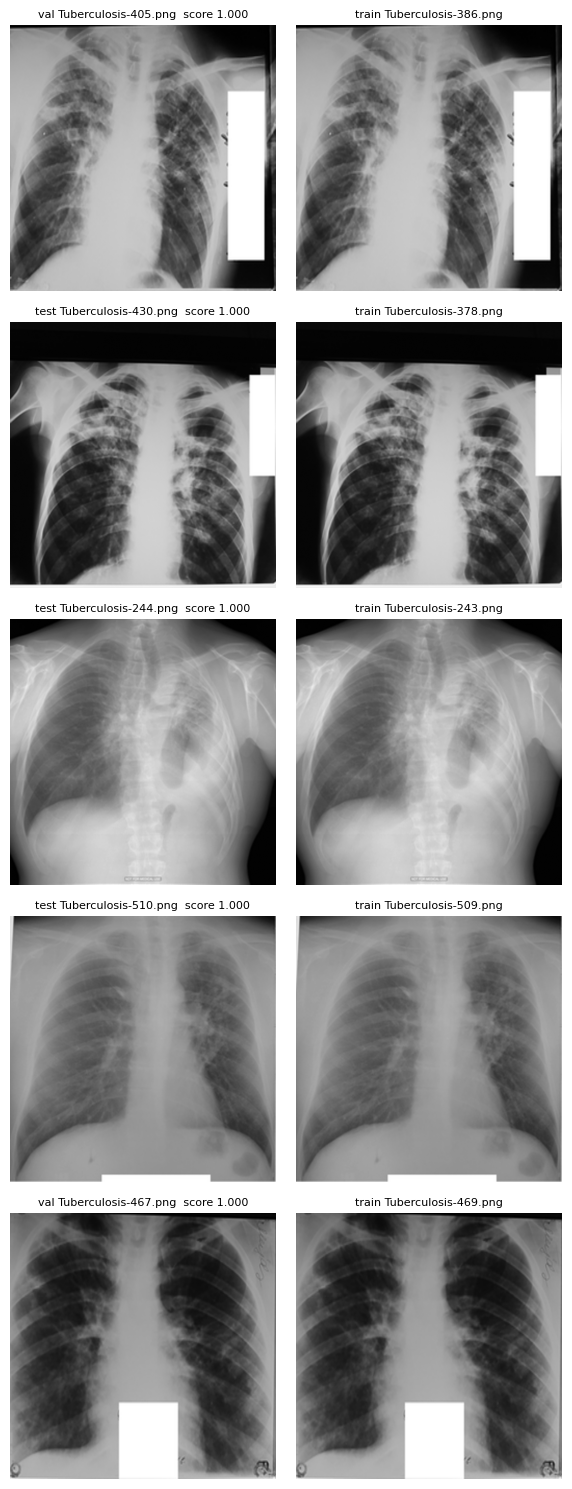

In [5]:
import matplotlib.pyplot as plt

def small(path):
    a = np.asarray(Image.open(path).convert('L').resize((32, 32)), dtype='float32').flatten()
    a = a - a.mean()
    return a / (np.linalg.norm(a) + 1e-8)

feats = np.stack([small(r[3]) for r in rows])
split_of = np.array([r[0] for r in rows])
train_idx = np.where(split_of == 'train')[0]
check_idx = np.where(split_of != 'train')[0]

sim = feats[check_idx] @ feats[train_idx].T
best = sim.max(axis=1)                      # best match in train for each val/test image
best_train = train_idx[sim.argmax(axis=1)]
print('best-match percentiles (50, 90, 99, max):', np.percentile(best, [50, 90, 99, 100]).round(3))
print('val/test images with a match above 0.99:', int((best > 0.99).sum()))

order = np.argsort(-best)[:5]
fig, ax = plt.subplots(5, 2, figsize=(6, 15))
for k, o in enumerate(order):
    a, b = check_idx[o], best_train[o]
    ax[k, 0].imshow(Image.open(rows[a][3]).convert('L'), cmap='gray')
    ax[k, 0].set_title(f'{rows[a][0]} {rows[a][2]}  score {best[o]:.3f}', fontsize=8)
    ax[k, 1].imshow(Image.open(rows[b][3]).convert('L'), cmap='gray')
    ax[k, 1].set_title(f'train {rows[b][2]}', fontsize=8)
    ax[k, 0].axis('off'); ax[k, 1].axis('off')
plt.tight_layout(); plt.show()

In [6]:
pairs = []
for o in np.where(best > 0.97)[0]:
    a, b = check_idx[o], best_train[o]
    pairs.append((rows[a][0], rows[a][1], rows[a][2], rows[b][2], round(float(best[o]), 4)))

print(len(pairs), 'pairs above 0.97')
for p in sorted(pairs, key=lambda p: -p[4]):
    print(p)

with open('/content/drive/MyDrive/EdgeTB_Project/results/near_duplicates.csv', 'w', newline='') as f:
    w = csv.writer(f)
    w.writerow(['split', 'class', 'val_or_test_file', 'train_file', 'score'])
    w.writerows(pairs)

6 pairs above 0.97
('val', 'TB', 'Tuberculosis-405.png', 'Tuberculosis-386.png', 1.0)
('val', 'TB', 'Tuberculosis-467.png', 'Tuberculosis-469.png', 1.0)
('test', 'TB', 'Tuberculosis-244.png', 'Tuberculosis-243.png', 1.0)
('test', 'TB', 'Tuberculosis-430.png', 'Tuberculosis-378.png', 1.0)
('test', 'TB', 'Tuberculosis-510.png', 'Tuberculosis-509.png', 1.0)
('test', 'TB', 'Tuberculosis-443.png', 'Tuberculosis-449.png', 0.9798)


In [7]:
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import roc_auc_score, confusion_matrix

model = load_model('/content/drive/MyDrive/EdgeTB_Project/models/mobilenetv2_tb.h5')
test = ImageDataGenerator(rescale=1./255).flow_from_directory(
    f'{BASE}/test', target_size=(224, 224), batch_size=32,
    class_mode='binary', shuffle=False)

probs = model.predict(test).flatten()
y = test.classes
names = [f.split('/')[-1] for f in test.filenames]

dup_test = {rows[check_idx[o]][2] for o in np.where(best > 0.99)[0]
            if rows[check_idx[o]][0] == 'test'}
keep = np.array([n not in dup_test for n in names])
print('removed from test:', sorted(dup_test), '| kept:', int(keep.sum()))

pred = (probs[keep] > 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(y[keep], pred).ravel()
print('sensitivity', round(tp / (tp + fn), 4), '| specificity', round(tn / (tn + fp), 4),
      '| AUC', round(roc_auc_score(y[keep], probs[keep]), 4))

Found 630 images belonging to 2 classes.
20/20 ━━━━━━━━━━━━━━━━━━━━ 40s 2s/step
removed from test: ['Tuberculosis-244.png', 'Tuberculosis-430.png', 'Tuberculosis-510.png'] | kept: 627
sensitivity 0.9804 | specificity 1.0 | AUC 1.0
